In [1]:
from jupyter_tikz import TexFragment
import os, sys
from IPython.display import display, HTML, Markdown, Math
import pandas as pd
import numpy as np
from scipy.stats import norm
from handcalcs.decorator import handcalc

# To find local version of the library
sys.path.append('../src')

from pmule import PredecessorTable, ProjectGraph, EarnedValue, pinta_tikz, plot_cargas, plot_curvas_valor_ganado

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

La federación de montaña ha adjudicado a su empresa la rehabilitación del refugio del Collado de la Braña, situado a 2.000 m de altitud y accesible únicamente por una pista forestal en mal estado. Las obras sólo pueden comenzar cuando se retira la nieve, a principios de mayo. Según los registros históricos, **la primera nevada importante llega hacia la semana 22** contada desde el inicio de la obra. Si el refugio no está cerrado y terminado para entonces, habrá que parar la obra hasta la primavera siguiente.

El equipo técnico ha preparado la información de la tabla adjunta. Para cada actividad se dispone de tres estimaciones de su duración, en semanas: optimista ($a$), más probable ($m$) y pesimista ($b$). Se indican también la duración tope, el coste planificado (BAC) en miles de euros, el coste unitario de reducción (CUR) en miles de euros por semana y el número de operarios necesarios. La tramitación de permisos y la inspección final no pueden acelerarse con dinero.

In [3]:
semana_nevada = 22
probabilidad_objetivo = 0.90
penalizacion_nevada = 80          # k€: temporada de reservas perdida y reposición de lo dañado
numero_de_iteraciones = 20000
limite_maximo_recursos = [8]*6 + [12]
semana_control = 11

pregunta_1 = Markdown(f"""1. Calcule la duración media y la desviación típica de cada actividad a partir de sus tres estimaciones. Dibuje los grafos Pert y Roy, determine el camino crítico y el calendario de ejecución. ¿Cuál es el presupuesto del proyecto?  """)
pregunta_2 = Markdown(f"""2. Utilizando la aproximación a la distribución normal:
    - ¿Qué probabilidad hay de terminar el refugio antes de la primera nevada (semana {semana_nevada})?
    - ¿Qué duración del proyecto puede comprometerse ante la federación con un {int(probabilidad_objetivo*100)}% de confianza?  """)
pregunta_3 = Markdown(f"""3. Repita el análisis mediante el método de MonteCarlo con {numero_de_iteraciones} iteraciones. Genere la duración de cada actividad con una distribución Beta-PERT de parámetros $a$, $m$ y $b$.
    - Compare los resultados con los del apartado anterior y explique las diferencias.
    - Calcule el índice de criticidad de cada ruta y de cada actividad. ¿Qué actividad no crítica debería vigilar el jefe de obra?  """)
pregunta_4 = Markdown(f"""4. Partiendo del proyecto original:
    - Determine, mediante el algoritmo de Ackoff-Sasieni, la reducción de mínimo coste necesaria para que la probabilidad de terminar antes de la nevada (aproximación normal) sea al menos del {int(probabilidad_objetivo*100)}%.
    - Si la obra no se termina antes de la nevada, la penalización estimada es de {penalizacion_nevada} k€. ¿Qué número de semanas de reducción minimiza el coste total esperado (sobrecoste de reducción más penalización esperada)?
    - Compruebe mediante MonteCarlo la probabilidad de terminar antes de la nevada con la opción elegida.  """)
pregunta_5 = Markdown(f"""5. Partiendo del proyecto original: la empresa sólo dispone de {limite_maximo_recursos[0]} operarios durante las seis primeras semanas, porque el resto termina otra obra en el valle, y de {limite_maximo_recursos[-1]} operarios a partir de entonces. Replanifique el proyecto. ¿Qué consecuencias tiene frente a la nevada?  """)
pregunta_6 = Markdown(f"""6. Partiendo del proyecto original: al final de la semana {semana_control} se realiza un punto de control, cuyos datos se adjuntan.
    - Calcule PV, EV, AC, CPI, SPI y la estimación del coste final (EAC).
    - Estime la duración final del proyecto mediante el método de la programación ganada (*Earned Schedule*). ¿Llegará el refugio a tiempo?  """)

In [4]:
for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(eval(item))

1. Calcule la duración media y la desviación típica de cada actividad a partir de sus tres estimaciones. Dibuje los grafos Pert y Roy, determine el camino crítico y el calendario de ejecución. ¿Cuál es el presupuesto del proyecto?  

2. Utilizando la aproximación a la distribución normal:
    - ¿Qué probabilidad hay de terminar el refugio antes de la primera nevada (semana 22)?
    - ¿Qué duración del proyecto puede comprometerse ante la federación con un 90% de confianza?  

3. Repita el análisis mediante el método de MonteCarlo con 20000 iteraciones. Genere la duración de cada actividad con una distribución Beta-PERT de parámetros $a$, $m$ y $b$.
    - Compare los resultados con los del apartado anterior y explique las diferencias.
    - Calcule el índice de criticidad de cada ruta y de cada actividad. ¿Qué actividad no crítica debería vigilar el jefe de obra?  

4. Partiendo del proyecto original:
    - Determine, mediante el algoritmo de Ackoff-Sasieni, la reducción de mínimo coste necesaria para que la probabilidad de terminar antes de la nevada (aproximación normal) sea al menos del 90%.
    - Si la obra no se termina antes de la nevada, la penalización estimada es de 80 k€. ¿Qué número de semanas de reducción minimiza el coste total esperado (sobrecoste de reducción más penalización esperada)?
    - Compruebe mediante MonteCarlo la probabilidad de terminar antes de la nevada con la opción elegida.  

5. Partiendo del proyecto original: la empresa sólo dispone de 8 operarios durante las seis primeras semanas, porque el resto termina otra obra en el valle, y de 12 operarios a partir de entonces. Replanifique el proyecto. ¿Qué consecuencias tiene frente a la nevada?  

6. Partiendo del proyecto original: al final de la semana 11 se realiza un punto de control, cuyos datos se adjuntan.
    - Calcule PV, EV, AC, CPI, SPI y la estimación del coste final (EAC).
    - Estime la duración final del proyecto mediante el método de la programación ganada (*Earned Schedule*). ¿Llegará el refugio a tiempo?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado del ejercicio"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  actividad, precedentes, a,  m,  b, duracion_tope, BAC,   cur,  recursos
     ('A',     '---    ',  1,  2,  3,      1,          6,     3,      2  ),
     ('B',     '---    ',  2,  3, 10,      4,          4, np.inf,     1  ),
     ('C',     'A      ',  2,  3,  4,      2,         18,     4,      4  ),
     ('D',     'B      ',  1,  2,  3,      1,          8,     5,      5  ),
     ('E',     'B,C    ',  1,  2,  9,      2,         24,     6,      2  ),
     ('F',     'C,D    ',  3,  4,  5,      3,         30,     7,      6  ),
     ('G',     'E,F    ',  3,  5,  7,      3,         45,     9,      6  ),
     ('H',     'E      ',  1,  2,  3,      1,         20,     2,      2  ),
     ('I',     'D      ',  2,  3,  4,      2,         15,     3,      3  ),
     ('J',     'G      ',  1,  2,  3,      1,         16,     4,      4  ),
     ('K',     'G,H,I  ',  2,  3,  4,      2,         22,     5,      4  ),
     ('L',     'J,K    ',  2,  3,  4,      2,         25,     8,      5  ),
     ('M',     'B      ',  1,  2,  3,      1,          5,     1,      1  ),
     ('N',     'L,M    ',  1,  1,  1,      1,          2, np.inf,     2  ),
] ,columns=['activity', 'predecessor', 'a', 'm', 'b', 'cap_duration', 'BAC', 'ucr', 'resources']).set_index('activity')

descripciones = pd.Series({
    'A': 'Estudio geotécnico y replanteo',
    'B': 'Permisos del Parque Natural',
    'C': 'Acondicionamiento de la pista de acceso',
    'D': 'Desmontaje de cubierta y demoliciones',
    'E': 'Porte de materiales en helicóptero',
    'F': 'Cimentación y muros de mampostería',
    'G': 'Estructura de madera y cubierta',
    'H': 'Instalación fotovoltaica y baterías',
    'I': 'Captación de agua y depuradora compacta',
    'J': 'Carpintería exterior y aislamiento',
    'K': 'Instalaciones interiores',
    'L': 'Acabados interiores y mobiliario',
    'M': 'Señalización de senderos y web de reservas',
    'N': 'Inspección final y apertura',
}, name='Descripción')

tabla = pd.concat([descripciones, datos_enunciado], axis=1)
tabla.columns = ['Descripción', 'Pred.', 'a', 'm', 'b', 'Duración <br> tope', 'BAC <br> (k€)', 'CUR <br> (k€/sem)', 'Operarios']
display(tabla.style.set_properties(**{'text-align': 'center'}).format(precision=0, na_rep='---'))

,Descripción,Pred.,a,m,b,Duración tope,BAC (k€),CUR (k€/sem),Operarios
A,Estudio geotécnico y replanteo,---,1,2,3,1,6,3,2
B,Permisos del Parque Natural,---,2,3,10,4,4,inf,1
C,Acondicionamiento de la pista de acceso,A,2,3,4,2,18,4,4
D,Desmontaje de cubierta y demoliciones,B,1,2,3,1,8,5,5
E,Porte de materiales en helicóptero,"B,C",1,2,9,2,24,6,2
F,Cimentación y muros de mampostería,"C,D",3,4,5,3,30,7,6
G,Estructura de madera y cubierta,"E,F",3,5,7,3,45,9,6
H,Instalación fotovoltaica y baterías,E,1,2,3,1,20,2,2
I,Captación de agua y depuradora compacta,D,2,3,4,2,15,3,3
J,Carpintería exterior y aislamiento,G,1,2,3,1,16,4,4


Datos del punto de control al final de la semana 11: duración real transcurrida (semanas), coste real (k€) y porcentaje realizado de cada actividad.

In [6]:
#| tbl-cap: "Datos del punto de control al final de la semana 11"
#| label: tbl-datosSeguimiento
datos_seguimiento = pd.DataFrame([
#  actividad, duracion_real, coste_real, realizado
     ('A',          2,            7,        100 ),
     ('B',          5,            4,        100 ),
     ('C',          3,           21,        100 ),
     ('D',          2,            8,        100 ),
     ('E',          4,           29,        100 ),
     ('F',          4,           27,         75 ),
     ('G',          0,            0,          0 ),
     ('H',          2,           14,         60 ),
     ('I',          3,           16,        100 ),
     ('J',          0,            0,          0 ),
     ('K',          0,            0,          0 ),
     ('L',          0,            0,          0 ),
     ('M',          2,            5,        100 ),
     ('N',          0,            0,          0 ),
] ,columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
tabla_seguimiento = datos_seguimiento.copy()
tabla_seguimiento.columns = ['Duración real', 'Coste real (k€)', 'Realizado (%)']
display(tabla_seguimiento.T.style.set_properties(**{'text-align': 'center'}))

activity,A,B,C,D,E,F,G,H,I,J,K,L,M,N
Duración real,2,5,3,2,4,4,0,2,3,0,0,0,2,0
Coste real (k€),7,4,21,8,29,27,0,14,16,0,0,0,5,0
Realizado (%),100,100,100,100,100,75,0,60,100,0,0,0,100,0


{{< pagebreak >}}

# Solución
## Apartado 1

In [7]:
display(pregunta_1)

1. Calcule la duración media y la desviación típica de cada actividad a partir de sus tres estimaciones. Dibuje los grafos Pert y Roy, determine el camino crítico y el calendario de ejecución. ¿Cuál es el presupuesto del proyecto?  

### Duración media y desviación típica de las actividades

Con las tres estimaciones de cada actividad se aplican las expresiones clásicas del método PERT, basadas en la distribución Beta:

$$D = \frac{a + 4m + b}{6} \qquad \sigma = \frac{b - a}{6} \qquad \sigma^2 = \left(\frac{b - a}{6}\right)^2$$

In [8]:
#| tbl-cap: "Duración media, desviación típica y varianza de las actividades"
#| label: tbl-duracionesMedias
datos_proyecto = datos_enunciado.copy()
datos_proyecto['duration'] = datos_proyecto.eval('(a + 4*m + b)/6').astype(int)
datos_proyecto['standard_deviation'] = datos_proyecto.eval('(b - a)/6')
datos_proyecto['variance'] = datos_proyecto['standard_deviation']**2
datos_proyecto[['a', 'm', 'b', 'duration', 'standard_deviation', 'variance']].round(2)

,a,m,b,duration,standard_deviation,variance
activity,,,,,,
A,1,2,3,2,0.33,0.11
B,2,3,10,4,1.33,1.78
C,2,3,4,3,0.33,0.11
D,1,2,3,2,0.33,0.11
E,1,2,9,3,1.33,1.78
F,3,4,5,4,0.33,0.11
G,3,5,7,5,0.67,0.44
H,1,2,3,2,0.33,0.11
I,2,3,4,3,0.33,0.11


Las actividades B (permisos) y E (helicóptero) tienen una estimación pesimista muy alejada de la más probable. La tramitación administrativa y los vuelos, que dependen de la meteorología, pueden retrasarse mucho, pero difícilmente adelantarse. Por eso son las actividades de mayor varianza.

### Presupuesto del proyecto

In [9]:
BAC_total = int(datos_proyecto['BAC'].sum())
Markdown(f"El presupuesto del proyecto se obtiene sumando los costes planificados de todas las actividades: **BAC = {BAC_total} k€**.")

El presupuesto del proyecto se obtiene sumando los costes planificados de todas las actividades: **BAC = 240 k€**.

### Cuadro de prelaciones expandido

Comenzamos construyendo el cuadro de prelaciones. Este cuadro nos permitirá construir los grafos Pert o Roy, si atendemos a la información de las filas; o comprobar si el grafo obtenido es correcto, atendiendo a la información de las columnas.

In [10]:
#| tbl-cap: "Cuadro de prelaciones expandido"
#| label: tbl-prelaciones
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
prelaciones.display_immediate_linkage_matrix()

,A,B,C,D,E,F,G,H,I,J,K,L,M,N
activities,,,,,,,,,,,,,,
A,,,,,,,,,,,,,,
B,,,,,,,,,,,,,,
C,True,,,,,,,,,,,,,
D,,True,,,,,,,,,,,,
E,,True,True,,,,,,,,,,,
F,,,True,True,,,,,,,,,,
G,,,,,True,True,,,,,,,,
H,,,,,True,,,,,,,,,
I,,,,True,,,,,,,,,,


### Grafo PERT con numeración de nodos

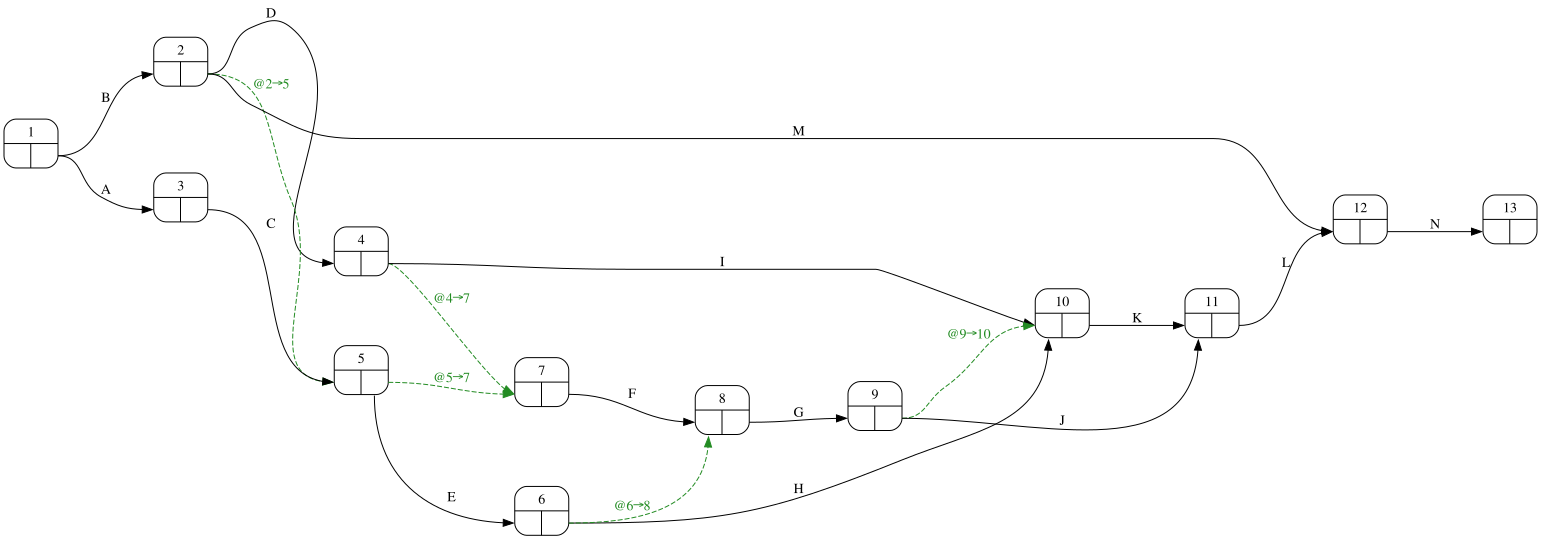

In [11]:
#| fig-cap: "Grafo Pert con indicación de los números de nodos"
#| label: fig-pertNumeracionNodos
proyecto = prelaciones.create_project()
proyecto.display_pert_construccion(tabla=prelaciones)

### Grafo Roy

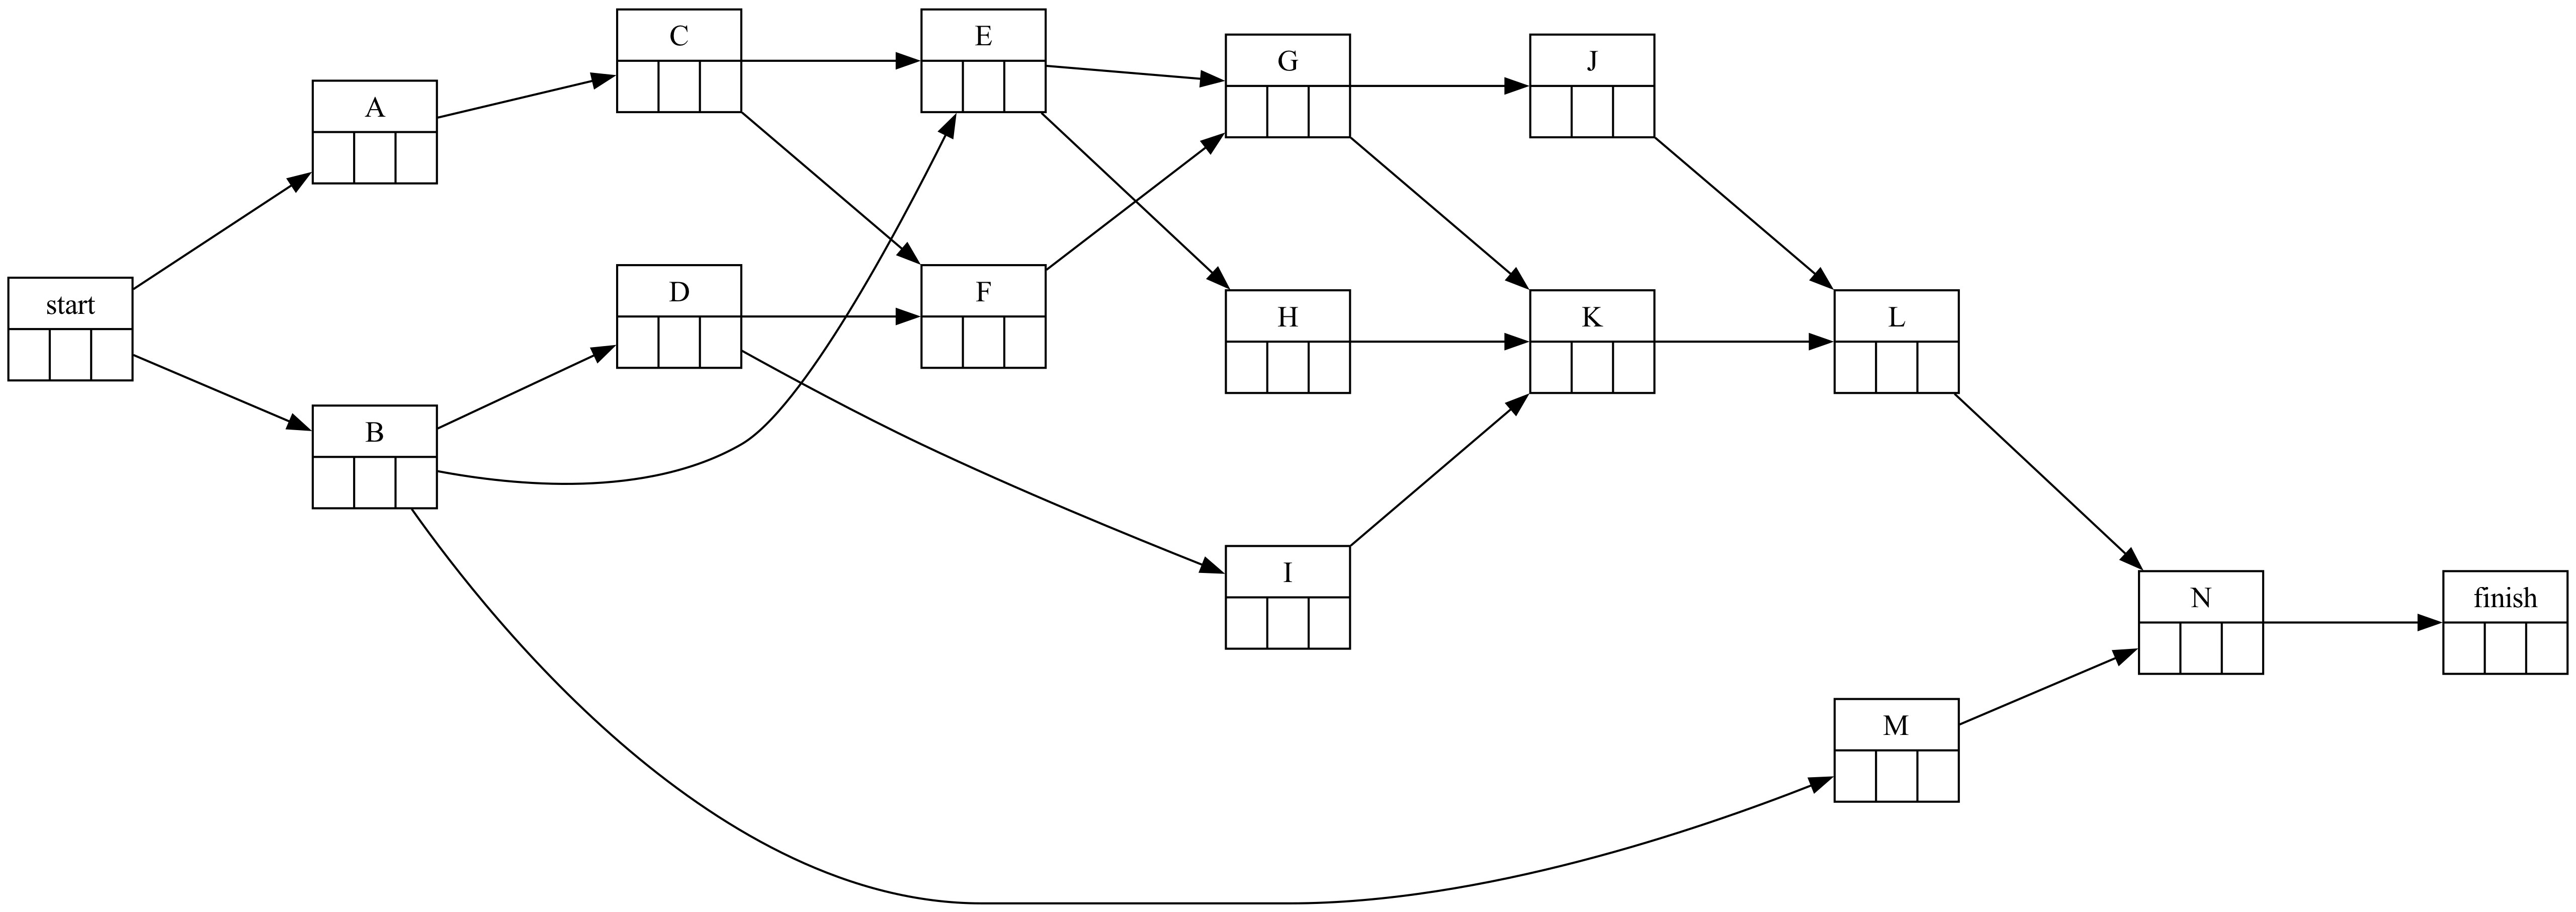

In [12]:
#| fig-cap: "Grafo Roy del proyecto"
#| label: fig-roy
proyecto.roy(ranksep=1.2, nodesep=1)

{{< pagebreak >}}

### Matriz de Zaderenko
Determinamos a continuación los tiempos tempranos y tardíos de los nodos del grafo Pert mediante el algoritmo de Zaderenko:

Matriz de Zaderenko paso a paso. El primer paso muestra el resultado final; a partir del siguiente se construye desde el principio (avance con los botones):

In [13]:
#| tbl-cap: "Matriz de Zaderenko para el cálculo de tiempos tempranos y tardíos"
#| label: tbl-Zaderenko
duraciones_medias = datos_proyecto['duration']
proyecto.display_zaderenko_tikz(duraciones_medias)

,1,2,3,4,5,6,7,8,9,10,11,12,13,early
1,,4.0,2.0,,,,,,,,,,,0.0
2,,,,2.0,0.0,,,,,,,2.0,,4.0
3,,,,,3.0,,,,,,,,,2.0
4,,,,,,,0.0,,,3.0,,,,6.0
5,,,,,,3.0,0.0,,,,,,,5.0
6,,,,,,,,0.0,,2.0,,,,8.0
7,,,,,,,,4.0,,,,,,6.0
8,,,,,,,,,5.0,,,,,10.0
9,,,,,,,,,,0.0,2.0,,,15.0
10,,,,,,,,,,,3.0,,,15.0


Los tiempos tempranos y tardíos obtenidos para cada nodo son:

In [14]:
#| tbl-cap: "Valores de los tiempos tempranos y tardíos de los nodos"
#| label: tbl-TempranosTardios
resultados_pert = proyecto.calculate_pert(durations=duraciones_medias)
resultados_pert['nodes']

,early,late
1,0,0
2,4,4
3,2,3
4,6,6
5,5,6
6,8,10
7,6,6
8,10,10
9,15,15
10,15,15


In [15]:
duracion_media_proyecto = int(proyecto.duration(durations=duraciones_medias))
Markdown(f"El tiempo del nodo final indica que la duración media del proyecto es de **{duracion_media_proyecto} semanas**.")

El tiempo del nodo final indica que la duración media del proyecto es de **22 semanas**.

### Holgura total y camino crítico

In [16]:
#| tbl-cap: "Holgura total de las actividades"
#| label: tbl-holguras
resultados_pert['activities'][['H_total']].T

,@2→5,@4→7,@5→7,@6→8,@9→10,A,B,C,D,E,F,G,H,I,J,K,L,M,N
H_total,2,0,1,2,0,1,0,1,0,2,0,0,5,6,1,0,0,15,0


Las actividades con holgura total nula forman el camino crítico:

In [17]:
proyecto.display_critical_path(durations=duraciones_medias)

- Route_7 :	B, D, F, G, K, L, N <br> 

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

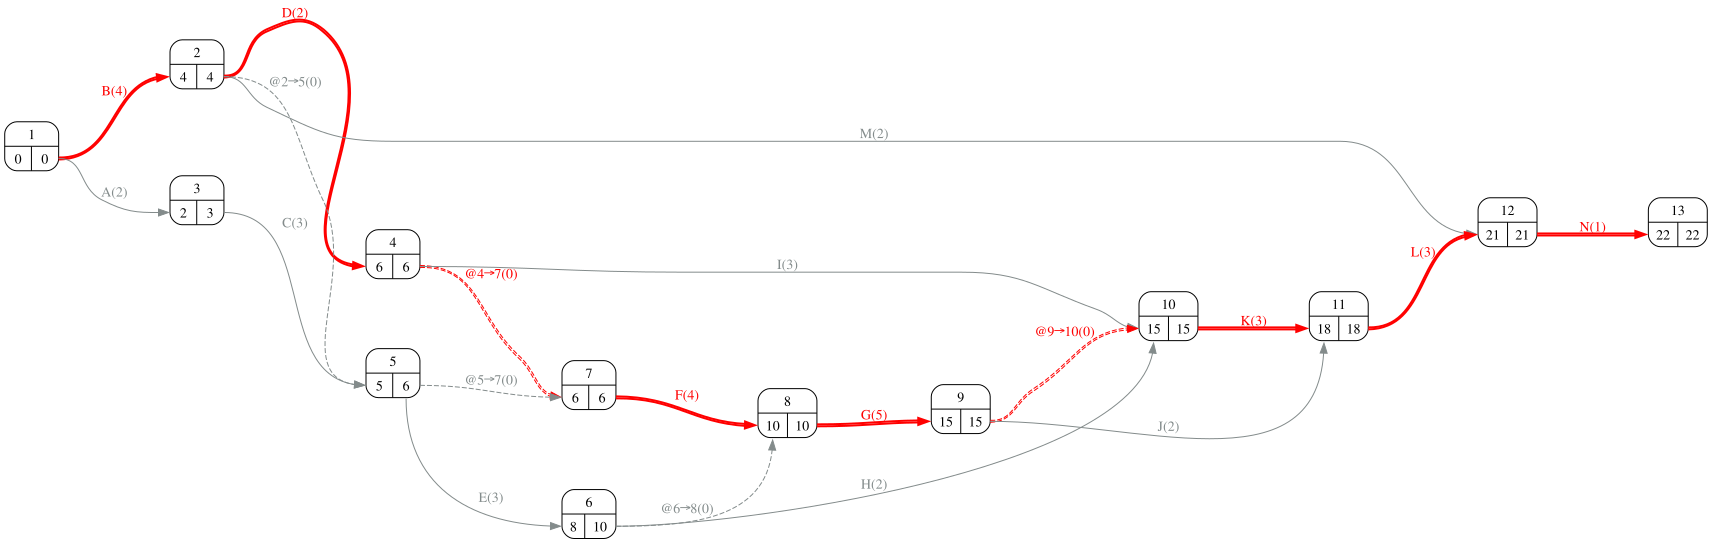

In [18]:
#| fig-cap: "Grafo Pert con indicación de tiempos y del camino crítico"
#| label: fig-pertCritico
proyecto.display_pert_pasos(duraciones_medias)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

In [ ]:
#| fig-cap: "Grafo Roy con indicación del camino crítico"
#| label: fig-royCritico
proyecto.display_roy_pasos(duraciones_medias)

Las actividades A y C (estudio geotécnico y pista) tienen una holgura de sólo una semana. La actividad J tiene también holgura uno. Volveremos sobre ello en el apartado 3.

### Calendario del proyecto

In [20]:
#| tbl-cap: "Calendario del proyecto"
#| label: tbl-calendario
calendario = proyecto.calendar(duraciones_medias).drop(columns='duracion').rename(columns={
    'inicio_mas_temprano': 'Inicio más temprano',
    'inicio_mas_tardio':   'Inicio más tardío',
    'fin_mas_temprano':    'Fin más temprano',
    'fin_mas_tardio':      'Fin más tardío',
    'H_total':             'Holgura total'})
proyecto.display_calendario(duraciones_medias)

,Inicio más temprano,Inicio más tardío,Fin más temprano,Fin más tardío,H_libre,H_independiente,Holgura total
activity,,,,,,,
A,0,1,2,3,0,0,1
B,0,0,4,4,0,0,0
C,2,3,5,6,0,0,1
D,4,4,6,6,0,0,0
E,5,7,8,10,0,0,2
F,6,6,10,10,0,0,0
G,10,10,15,15,0,0,0
H,8,13,10,15,5,3,5
I,6,12,9,15,6,6,6


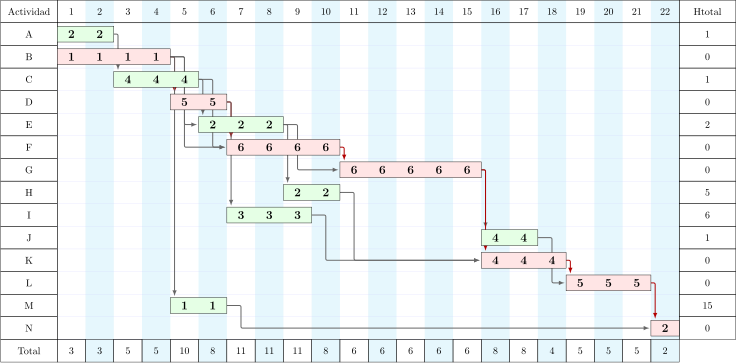

In [21]:
#| fig-cap: "Diagrama de Gantt del proyecto"
#| label: fig-gantt
gantt_df, dibujo = proyecto.gantt(datos_proyecto, 'duration', 'resources', total='fila', holguras=True, tikz=True)
pinta_tikz(dibujo)

{{< pagebreak >}}

## Apartado 2

In [22]:
display(pregunta_2)

2. Utilizando la aproximación a la distribución normal:
    - ¿Qué probabilidad hay de terminar el refugio antes de la primera nevada (semana 22)?
    - ¿Qué duración del proyecto puede comprometerse ante la federación con un 90% de confianza?  

### Caracterización de la distribución normal
Según el teorema del límite central, la duración del proyecto se aproxima por una distribución normal. Su media es la duración obtenida con las duraciones medias de las actividades. Su varianza es la mayor de las varianzas de las rutas del camino crítico.

In [23]:
#| tbl-cap: "Varianza de las rutas del camino crítico"
#| label: tbl-varianzaRutas
desviacion_proyecto, varianza_caminos = proyecto.standard_deviation(durations=duraciones_medias,
                                                                    variances=datos_proyecto['variance'])
varianza_caminos

,Activities,Variance
Route_7,"B, D, F, G, K, L, N",2.67


In [24]:
Markdown(f"La duración del proyecto se modela entonces como $T \\sim N(\\mu={duracion_media_proyecto}, \\ \\sigma={desviacion_proyecto:.2f})$.")

La duración del proyecto se modela entonces como $T \sim N(\mu=22, \ \sigma=1.63)$.

### Probabilidad de terminar antes de la nevada

In [25]:
probabilidad_normal = norm.cdf(semana_nevada, loc=duracion_media_proyecto, scale=desviacion_proyecto)
from pmule import display_normal_tikz
display_normal_tikz(duracion_media_proyecto, desviacion_proyecto, hasta=semana_nevada)
Markdown(f"""$P(T \\le {semana_nevada}) = \\Phi\\left(\\frac{{{semana_nevada} - {duracion_media_proyecto}}}{{{desviacion_proyecto:.2f}}}\\right) = $ **{probabilidad_normal*100:.1f}%**.

La duración media del proyecto coincide con la semana de la nevada. Planificar así equivale a lanzar una moneda al aire.""")

$P(T \le 22) = \Phi\left(\frac{22 - 22}{1.63}\right) = $ **50.0%**.

La duración media del proyecto coincide con la semana de la nevada. Planificar así equivale a lanzar una moneda al aire.

### Duración comprometida con un 90% de confianza

In [26]:
duracion_comprometida_normal = norm.ppf(probabilidad_objetivo, loc=duracion_media_proyecto, scale=desviacion_proyecto)
from pmule import display_normal_tikz
display_normal_tikz(duracion_media_proyecto, desviacion_proyecto, percentil=probabilidad_objetivo)
Markdown(f"""$T_{{{int(probabilidad_objetivo*100)}}} = \\mu + z_{{{probabilidad_objetivo}}}\\,\\sigma = {duracion_media_proyecto} + {norm.ppf(probabilidad_objetivo):.4f} \\times {desviacion_proyecto:.2f} = $ **{duracion_comprometida_normal:.2f} semanas**.

Esa fecha cae más de dos semanas después de la nevada.""")

$T_{90} = \mu + z_{0.9}\,\sigma = 22 + 1.2816 \times 1.63 = $ **24.09 semanas**.

Esa fecha cae más de dos semanas después de la nevada.

{{< pagebreak >}}

## Apartado 3

In [27]:
display(pregunta_3)

3. Repita el análisis mediante el método de MonteCarlo con 20000 iteraciones. Genere la duración de cada actividad con una distribución Beta-PERT de parámetros $a$, $m$ y $b$.
    - Compare los resultados con los del apartado anterior y explique las diferencias.
    - Calcule el índice de criticidad de cada ruta y de cada actividad. ¿Qué actividad no crítica debería vigilar el jefe de obra?  

### Generación de las duraciones mediante la distribución Beta-PERT

La distribución Beta-PERT es la que justifica las fórmulas del apartado 1. Una variable Beta-PERT de parámetros $(a, m, b)$ se obtiene como $X = a + (b - a)\,Y$, donde $Y \sim \text{Beta}(\alpha, \beta)$ con

$$\alpha = 1 + 4\,\frac{m - a}{b - a} \qquad \beta = 1 + 4\,\frac{b - m}{b - a}$$

Su media es precisamente $\frac{a+4m+b}{6}$. A diferencia de la normal, es asimétrica. Esto permite reflejar que los permisos o los vuelos pueden retrasarse mucho más de lo que pueden adelantarse. Cuando $a = b$, la duración es determinista.

In [28]:
def muestras_beta_pert(a, m, b, size, rng):
    if b == a:
        return np.full(size, float(a))
    alfa = 1 + 4 * (m - a) / (b - a)
    beta = 1 + 4 * (b - m) / (b - a)
    return a + (b - a) * rng.beta(alfa, beta, size)

rng = np.random.default_rng(2026)
duraciones_montecarlo = pd.DataFrame({actividad: muestras_beta_pert(fila.a, fila.m, fila.b, numero_de_iteraciones, rng)
                                      for actividad, fila in datos_proyecto.iterrows()})

In [29]:
#| tbl-cap: "Primeras iteraciones de las duraciones generadas"
#| label: tbl-duracionesMontecarlo
duraciones_montecarlo.head().round(2)

,A,B,C,D,E,F,G,H,I,J,K,L,M,N
0,2.44,2.43,3.00,2.31,1.56,3.65,4.00,2.18,3.45,1.64,2.80,3.17,2.60,1.0
1,2.28,2.77,3.81,1.60,2.37,3.63,5.92,2.43,2.40,2.08,3.55,3.52,2.06,1.0
2,1.72,3.69,3.56,2.40,3.52,4.06,5.18,2.32,2.43,2.16,3.43,3.01,2.08,1.0
3,1.93,3.26,3.24,2.27,2.41,3.77,5.55,1.87,2.95,1.64,2.70,3.05,1.83,1.0
4,1.91,8.23,2.33,1.61,1.29,3.75,5.82,2.59,3.12,1.92,2.43,2.90,2.72,1.0


In [30]:
#| tbl-cap: "Comprobación: media y desviación típica muestrales frente a las teóricas"
#| label: tbl-comprobacionMuestras
pd.DataFrame({'Media teórica': datos_proyecto['duration'],
              'Media muestral': duraciones_montecarlo.mean(),
              'σ teórica': datos_proyecto['standard_deviation'],
              'σ muestral': duraciones_montecarlo.std()}).round(2).T

,A,B,C,D,E,F,G,H,I,J,K,L,M,N
Media teórica,2.00,4.00,3.00,2.00,3.00,4.00,5.00,2.00,3.00,2.00,3.00,3.00,2.00,1.0
Media muestral,2.00,4.00,3.00,2.00,3.01,4.00,5.00,2.00,3.00,2.01,3.00,2.99,2.00,1.0
σ teórica,0.33,1.33,0.33,0.33,1.33,0.33,0.67,0.33,0.33,0.33,0.33,0.33,0.33,0.0
σ muestral,0.38,1.31,0.38,0.38,1.31,0.38,0.76,0.38,0.38,0.38,0.38,0.38,0.38,0.0


Las medias muestrales coinciden con las teóricas. Las desviaciones típicas de las actividades simétricas salen algo mayores que $(b-a)/6$. No es un error: la fórmula $\sigma = (b-a)/6$ es una aproximación, y la desviación típica exacta de la Beta-PERT simétrica ($\alpha=\beta=3$) es $(b-a)/\sqrt{28} \approx (b-a)/5.3$.

### Matriz de caminos
Cada fila de la matriz de caminos indica qué actividades forman cada una de las rutas del grafo:

In [31]:
#| tbl-cap: "Matriz de caminos del proyecto"
#| label: tbl-matrizCaminos
path_matrix = proyecto.path_matrix(dummies=False)
proyecto.display_path_matrix(dummies=False)

,A,B,C,D,E,F,G,H,I,J,K,L,M,N
Route_1,1,0,1,0,1,0,1,0,0,1,0,1,0,1
Route_2,1,0,1,0,1,0,1,0,0,0,1,1,0,1
Route_3,1,0,1,0,1,0,0,1,0,0,1,1,0,1
Route_4,1,0,1,0,0,1,1,0,0,1,0,1,0,1
Route_5,1,0,1,0,0,1,1,0,0,0,1,1,0,1
Route_6,0,1,0,1,0,1,1,0,0,1,0,1,0,1
Route_7,0,1,0,1,0,1,1,0,0,0,1,1,0,1
Route_8,0,1,0,1,0,0,0,0,1,0,1,1,0,1
Route_9,0,1,0,0,1,0,1,0,0,1,0,1,0,1
Route_10,0,1,0,0,1,0,1,0,0,0,1,1,0,1


### Duración del proyecto en cada iteración
Multiplicando las duraciones de cada iteración por la traspuesta de la matriz de caminos obtenemos la duración de todas las rutas. La duración del proyecto en cada iteración es la de la ruta más larga.

In [32]:
duraciones_montecarlo = duraciones_montecarlo[path_matrix.columns]
duraciones_rutas = duraciones_montecarlo @ path_matrix.T
duracion_proyecto_mc = duraciones_rutas.max(axis='columns')

In [33]:
#| tbl-cap: "Duración de las rutas y del proyecto en las primeras iteraciones"
#| label: tbl-duracionesRutasMC
pd.concat([duraciones_rutas, duracion_proyecto_mc.rename('Proyecto')], axis=1).head().round(2)

,Route_1,Route_2,Route_3,Route_4,Route_5,Route_6,Route_7,Route_8,Route_9,Route_10,Route_11,Route_12,Route_13,Route_14,Proyecto
0,16.80,17.96,16.14,18.90,20.06,18.20,19.36,15.16,13.79,14.95,13.13,15.89,17.05,6.03,20.06
1,20.98,22.45,18.96,22.24,23.71,20.52,21.99,14.84,17.66,19.13,15.64,18.92,20.39,5.83,23.71
2,20.13,21.41,18.55,20.67,21.95,21.48,22.75,15.95,18.55,19.82,16.96,19.08,20.36,6.77,22.75
3,18.82,19.88,16.20,20.18,21.24,20.54,21.60,15.23,16.91,17.97,14.29,18.27,19.33,6.09,21.60
4,17.18,17.69,14.46,19.64,20.15,25.23,25.74,19.28,21.16,21.67,18.44,23.62,24.13,11.95,25.74


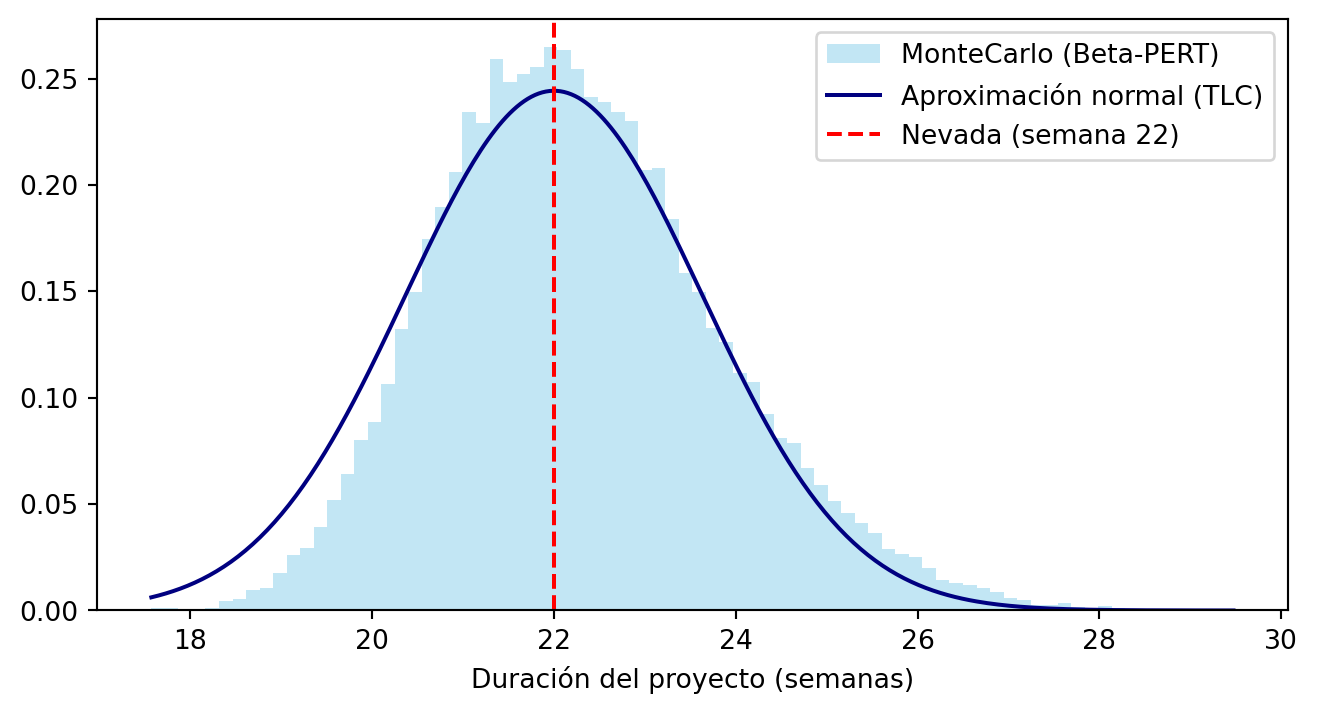

In [34]:
#| fig-cap: "Distribución de la duración del proyecto: MonteCarlo frente a la aproximación normal"
#| label: fig-histogramaMC
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(duracion_proyecto_mc, bins=80, density=True, alpha=0.5, color='skyblue', label='MonteCarlo (Beta-PERT)')
x = np.linspace(duracion_proyecto_mc.min(), duracion_proyecto_mc.max(), 300)
ax.plot(x, norm.pdf(x, duracion_media_proyecto, desviacion_proyecto), color='navy', label='Aproximación normal (TLC)')
ax.axvline(semana_nevada, color='red', linestyle='--', label=f'Nevada (semana {semana_nevada})')
ax.set_xlabel('Duración del proyecto (semanas)')
ax.legend()
plt.show()

In [35]:
media_mc = duracion_proyecto_mc.mean()
desviacion_mc = duracion_proyecto_mc.std()
probabilidad_mc = (duracion_proyecto_mc <= semana_nevada).mean()
duracion_comprometida_mc = duracion_proyecto_mc.quantile(probabilidad_objetivo, interpolation='higher')

In [36]:
#| tbl-cap: "Comparación entre la aproximación normal y MonteCarlo"
#| label: tbl-comparacionTLCMC
pd.DataFrame({
    'Aproximación normal': [duracion_media_proyecto, desviacion_proyecto, probabilidad_normal*100, duracion_comprometida_normal],
    'MonteCarlo':          [media_mc, desviacion_mc, probabilidad_mc*100, duracion_comprometida_mc]},
    index=['Duración media', 'Desviación típica', f'P(T ≤ {semana_nevada}) (%)', f'Duración para {int(probabilidad_objetivo*100)}%']).round(2)

,Aproximación normal,MonteCarlo
Duración media,22.00,22.29
Desviación típica,1.63,1.56
P(T ≤ 22) (%),50.00,45.64
Duración para 90%,24.09,24.38


### Interpretación de las diferencias

- **La duración media de MonteCarlo es mayor que la del método PERT.** El método PERT sólo considera la ruta crítica. En cada iteración, sin embargo, la duración del proyecto es el *máximo* de todas las rutas, y el máximo de varias variables aleatorias tiene una media mayor que la media de cualquiera de ellas (sesgo de fusión o *merge bias*). Las rutas casi críticas "empujan" la duración hacia arriba.
- **La probabilidad de llegar a tiempo es, por tanto, algo menor** de lo que indica la aproximación normal. El método PERT clásico es optimista.
- **La desviación típica de MonteCarlo es algo menor.** Por eso la diferencia en la duración para el 90% es más pequeña de lo que la diferencia de medias podría sugerir. En las iteraciones en que los permisos (B, muy variable) se resuelven pronto, la ruta crítica pasa a ser A-C-…, mucho menos variable. Eso recorta la cola derecha.

### Índices de criticidad

El índice de criticidad de una ruta es la fracción de iteraciones en que esa ruta es la más larga. El de una actividad es la fracción de iteraciones en que la actividad pertenece a la ruta más larga.

In [37]:
#| tbl-cap: "Índice de criticidad de las rutas (se omiten las que nunca resultan críticas)"
#| label: tbl-criticidadRutas
ruta_critica_por_iteracion = duraciones_rutas.idxmax(axis='columns')
criticidad_rutas = ruta_critica_por_iteracion.value_counts(normalize=True).rename('Índice de criticidad (%)') * 100
actividades_ruta = path_matrix.apply(lambda fila: '-'.join(fila.index[fila == 1]), axis=1).rename('Actividades')
pd.concat([actividades_ruta, criticidad_rutas], axis=1).dropna().sort_values('Índice de criticidad (%)', ascending=False).round(2)

,Actividades,Índice de criticidad (%)
Route_7,B-D-F-G-K-L-N,64.78
Route_5,A-C-F-G-K-L-N,20.45
Route_2,A-C-E-G-K-L-N,11.09
Route_6,B-D-F-G-J-L-N,1.97
Route_4,A-C-F-G-J-L-N,0.72
Route_10,B-E-G-K-L-N,0.66
Route_1,A-C-E-G-J-L-N,0.32
Route_9,B-E-G-J-L-N,0.01


In [38]:
#| tbl-cap: "Índice de criticidad de las actividades frente a su holgura total"
#| label: tbl-criticidadActividades
criticidad_actividades = path_matrix.loc[ruta_critica_por_iteracion].mean() * 100
pd.DataFrame({'Holgura total': resultados_pert['activities']['H_total'],
              'Índice de criticidad (%)': criticidad_actividades}).round(1).T

,@2→5,@4→7,@5→7,@6→8,@9→10,A,B,C,D,E,F,G,H,I,J,K,L,M,N
Holgura total,2.0,0.0,1.0,2.0,0.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,5.0,6.0,1.0,0.0,0.0,15.0,0.0
Índice de criticidad (%),NaN,NaN,NaN,NaN,NaN,32.6,67.4,32.6,66.7,12.1,87.9,100.0,0.0,0.0,3.0,97.0,100.0,0.0,100.0


In [39]:
criticidad_A = criticidad_actividades['A']
Markdown(f"""El análisis determinista dice que las actividades A y C no son críticas, porque tienen una semana de holgura. Sin embargo, **en el {criticidad_A:.0f}% de las iteraciones forman parte de la ruta más larga**. El jefe de obra debe vigilar especialmente **el acondicionamiento de la pista (C)**, que es la actividad de mayor coste de las dos, y el estudio geotécnico (A). Un retraso de sólo una semana en cualquiera de ellas las convierte en críticas.

Por el contrario, M (señalización y web) no es crítica en ninguna iteración: su holgura de {int(resultados_pert['activities'].loc['M', 'H_total'])} semanas es más que suficiente.""")

El análisis determinista dice que las actividades A y C no son críticas, porque tienen una semana de holgura. Sin embargo, **en el 33% de las iteraciones forman parte de la ruta más larga**. El jefe de obra debe vigilar especialmente **el acondicionamiento de la pista (C)**, que es la actividad de mayor coste de las dos, y el estudio geotécnico (A). Un retraso de sólo una semana en cualquiera de ellas las convierte en críticas.

Por el contrario, M (señalización y web) no es crítica en ninguna iteración: su holgura de 15 semanas es más que suficiente.

{{< pagebreak >}}

## Apartado 4

In [40]:
display(pregunta_4)

4. Partiendo del proyecto original:
    - Determine, mediante el algoritmo de Ackoff-Sasieni, la reducción de mínimo coste necesaria para que la probabilidad de terminar antes de la nevada (aproximación normal) sea al menos del 90%.
    - Si la obra no se termina antes de la nevada, la penalización estimada es de 80 k€. ¿Qué número de semanas de reducción minimiza el coste total esperado (sobrecoste de reducción más penalización esperada)?
    - Compruebe mediante MonteCarlo la probabilidad de terminar antes de la nevada con la opción elegida.  

### Reducción necesaria para alcanzar el 90% de probabilidad

Aplicamos el algoritmo de Ackoff-Sasieni semana a semana. Tras cada reducción recalculamos la duración media, la varianza del camino crítico (que puede cambiar al aparecer nuevas rutas críticas) y la probabilidad de terminar antes de la nevada. Se supone que acelerar una actividad no altera la varianza de su duración.

In [41]:
def analiza_reduccion(semanas):
    if semanas == 0:
        duraciones = duraciones_medias.copy()
        opciones = dict()
    else:
        _, opciones, duraciones, _ = proyecto.ackoff(durations=duraciones_medias,
                                                     min_durations=datos_proyecto['cap_duration'],
                                                     costs=datos_proyecto['ucr'],
                                                     reduction=semanas)
    duracion = int(proyecto.duration(duraciones))
    desviacion, _ = proyecto.standard_deviation(durations=duraciones, variances=datos_proyecto['variance'])
    sobrecoste = sum(datos_proyecto.loc[actividad, 'ucr'] for paso in opciones.values() for actividad in paso)
    probabilidad = norm.cdf(semana_nevada, loc=duracion, scale=desviacion)
    return dict(duracion=duracion,
                desviacion=desviacion,
                sobrecoste=sobrecoste,
                probabilidad=probabilidad,
                reducidas=', '.join(actividad for paso in opciones.values() for actividad in paso),
                duraciones=duraciones)

analisis = {semanas: analiza_reduccion(semanas) for semanas in range(0, 6)}

In [42]:
#| tbl-cap: "Efecto de cada semana de reducción sobre la probabilidad de terminar antes de la nevada"
#| label: tbl-reducciones
tabla_reducciones = pd.DataFrame({semanas: {'Actividades reducidas': r['reducidas'],
                                            'Duración media': r['duracion'],
                                            'σ proyecto': round(r['desviacion'], 2),
                                            'Sobrecoste (k€)': r['sobrecoste'],
                                            f'P(T ≤ {semana_nevada}) (%)': round(r['probabilidad']*100, 1)}
                                  for semanas, r in analisis.items()}).T
tabla_reducciones.index.name = 'Semanas reducidas'
tabla_reducciones

,Actividades reducidas,Duración media,σ proyecto,Sobrecoste (k€),P(T ≤ 22) (%)
Semanas reducidas,,,,,
0,,22,1.63,0,50.0
1,D,21,1.63,5.0,73.0
2,"D, K",20,1.63,10.0,89.0
3,"D, K, F",19,1.63,17.0,96.7
4,"D, K, F, L",18,1.63,25.0,99.3
5,"D, K, F, L, G",17,1.63,34.0,99.9


In [43]:
semanas_necesarias = min(semanas for semanas, r in analisis.items() if r['probabilidad'] >= probabilidad_objetivo)
opcion_90 = analisis[semanas_necesarias]

El cuadro completo del algoritmo de Ackoff-Sasieni para la reducción necesaria es:

In [44]:
#| tbl-cap: "Cuadro del algoritmo de Ackoff-Sasieni"
#| label: tbl-ackoff
ackoff, best_option, duracion_ackoff, disponibles = proyecto.ackoff(durations=duraciones_medias,
                                                                    min_durations=datos_proyecto['cap_duration'],
                                                                    costs=datos_proyecto['ucr'],
                                                                    reduction=semanas_necesarias)
proyecto.display_ackoff_pasos_tikz(
    durations=duraciones_medias,
    min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'],
    reduction=semanas_necesarias)

,A,B,C,D,E,F,G,H,I,J,K,L,M,N,0,1,2,3
Route_1,3.0,,4.0,,6.0,,9.0,,,4.0,,8.0,,inf,19.0,19.0,19.0,19.0
Route_2,3.0,,4.0,,6.0,,9.0,,,,5.0,8.0,,inf,20.0,20.0,19.0,19.0
Route_3,3.0,,4.0,,6.0,,,2.0,,,5.0,8.0,,inf,17.0,17.0,16.0,16.0
Route_4,3.0,,4.0,,,7.0,9.0,,,4.0,,8.0,,inf,20.0,20.0,20.0,19.0
Route_5,3.0,,4.0,,,7.0,9.0,,,,5.0,8.0,,inf,21.0,21.0,20.0,19.0
Route_6,,inf,,5.0,,7.0,9.0,,,4.0,,8.0,,inf,21.0,20.0,20.0,19.0
Route_7,,inf,,5.0,,7.0,9.0,,,,5.0,8.0,,inf,22.0,21.0,20.0,19.0
Route_8,,inf,,5.0,,,,,3.0,,5.0,8.0,,inf,16.0,15.0,14.0,14.0
Route_9,,inf,,,6.0,,9.0,,,4.0,,8.0,,inf,18.0,18.0,18.0,18.0
Route_10,,inf,,,6.0,,9.0,,,,5.0,8.0,,inf,19.0,19.0,18.0,18.0


In [45]:
Markdown(f"""Reducir {semanas_necesarias - 1} semanas deja la probabilidad en {analisis[semanas_necesarias - 1]['probabilidad']*100:.1f}%, que se queda justo por debajo del objetivo. Hay que reducir **{semanas_necesarias} semanas**, acortando las actividades {opcion_90['reducidas']}. El sobrecoste es de **{opcion_90['sobrecoste']} k€** y la probabilidad de terminar antes de la nevada pasa a ser del **{opcion_90['probabilidad']*100:.1f}%**.""")

Reducir 2 semanas deja la probabilidad en 89.0%, que se queda justo por debajo del objetivo. Hay que reducir **3 semanas**, acortando las actividades D, K, F. El sobrecoste es de **17.0 k€** y la probabilidad de terminar antes de la nevada pasa a ser del **96.7%**.

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

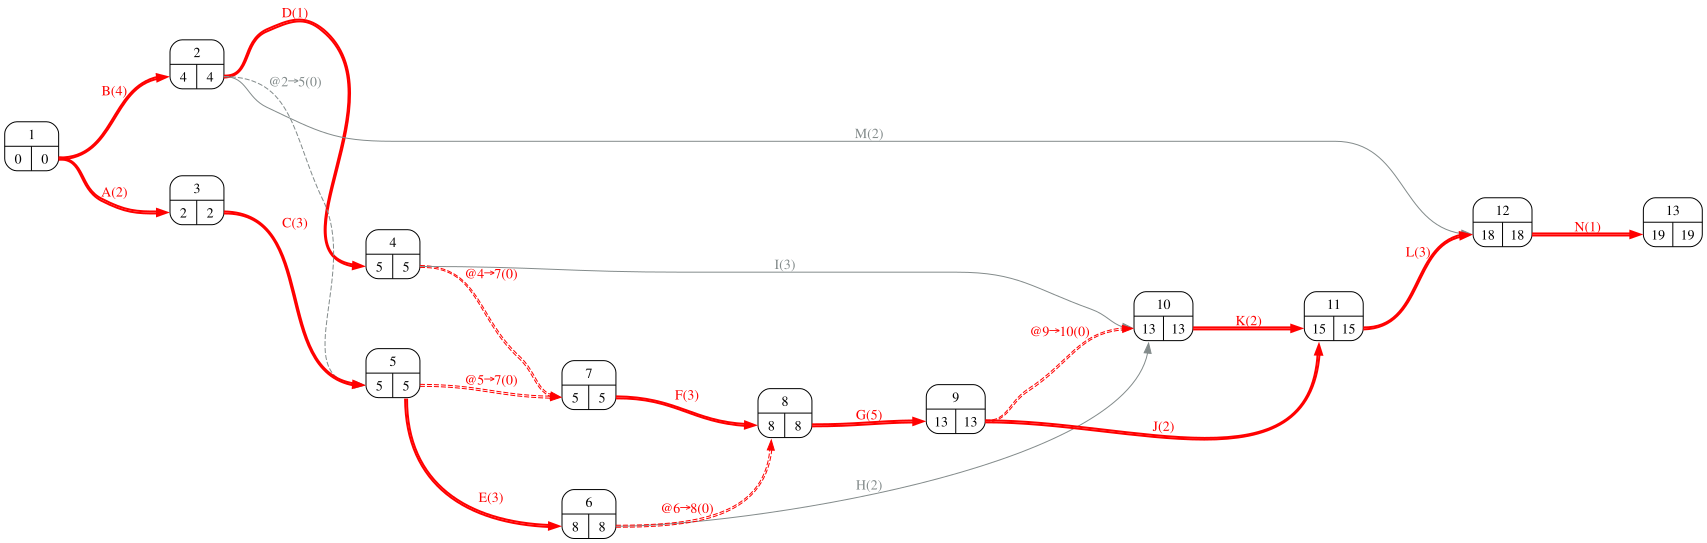

In [46]:
#| fig-cap: "Grafo Pert del proyecto tras la reducción: aparecen nuevas rutas críticas"
#| label: fig-pertReducido
proyecto.display_pert_pasos(opcion_90['duraciones'])

### Minimización del coste total esperado

Reducir cuesta dinero, pero no reducir también: con probabilidad $1 - P(T \le 22)$ se paga la penalización. El coste total esperado de cada alternativa es:

$$E[C] = \text{Sobrecoste de reducción} + \left(1 - P(T \le 22)\right) \times \text{Penalización}$$

In [47]:
#| tbl-cap: "Coste total esperado para cada número de semanas de reducción"
#| label: tbl-costeEsperado
coste_esperado = pd.DataFrame({semanas: {'Sobrecoste (k€)': r['sobrecoste'],
                                         'P(no terminar) (%)': round((1 - r['probabilidad'])*100, 1),
                                         'Penalización esperada (k€)': round((1 - r['probabilidad'])*penalizacion_nevada, 2),
                                         'Coste total esperado (k€)': round(r['sobrecoste'] + (1 - r['probabilidad'])*penalizacion_nevada, 2)}
                               for semanas, r in analisis.items()}).T
coste_esperado.index.name = 'Semanas reducidas'
coste_esperado.style.highlight_min(subset=['Coste total esperado (k€)'], color='yellow').format(precision=2)

,Sobrecoste (k€),P(no terminar) (%),Penalización esperada (k€),Coste total esperado (k€)
Semanas reducidas,,,,
0,0.00,50.00,40.00,40.00
1,5.00,27.00,21.61,26.61
2,10.00,11.00,8.83,18.83
3,17.00,3.30,2.65,19.65
4,25.00,0.70,0.57,25.57
5,34.00,0.10,0.09,34.09


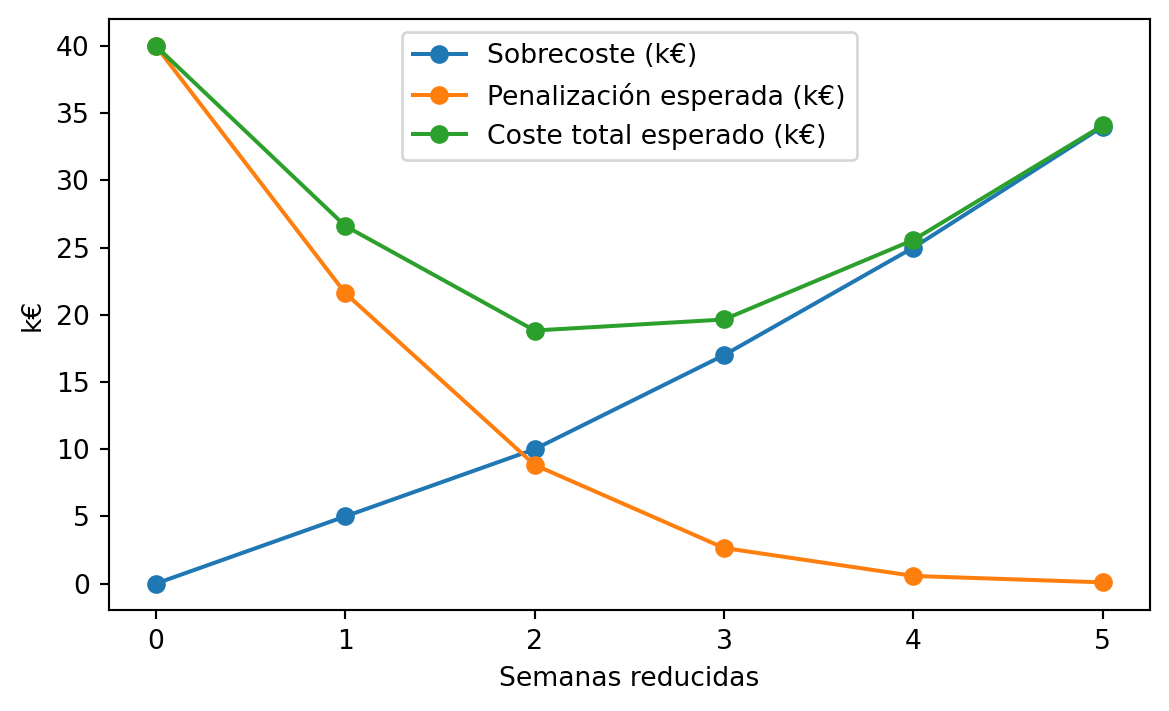

In [48]:
#| fig-cap: "Compromiso entre el sobrecoste de reducción y la penalización esperada"
#| label: fig-costeEsperado
ax = coste_esperado[['Sobrecoste (k€)', 'Penalización esperada (k€)', 'Coste total esperado (k€)']].astype(float).plot(marker='o', figsize=(7, 4))
ax.set_xlabel('Semanas reducidas')
ax.set_ylabel('k€')
plt.show()

In [49]:
semanas_optimas = int(coste_esperado['Coste total esperado (k€)'].astype(float).idxmin())
Markdown(f"""El coste total esperado es mínimo con **{semanas_optimas} semanas de reducción**: {coste_esperado.loc[semanas_optimas, 'Coste total esperado (k€)']} k€.

Los dos criterios no tienen por qué coincidir. El criterio del {int(probabilidad_objetivo*100)}% impone un nivel de riesgo fijado de antemano. El criterio del coste esperado compara directamente el precio de cada semana con lo que esa semana ahorra en penalización esperada. A partir de cierto punto, cada semana adicional cuesta más de lo que ahorra en riesgo, porque la penalización esperada ya es pequeña y las actividades que quedan por reducir son cada vez más caras.""")

El coste total esperado es mínimo con **2 semanas de reducción**: 18.83 k€.

Los dos criterios no tienen por qué coincidir. El criterio del 90% impone un nivel de riesgo fijado de antemano. El criterio del coste esperado compara directamente el precio de cada semana con lo que esa semana ahorra en penalización esperada. A partir de cierto punto, cada semana adicional cuesta más de lo que ahorra en riesgo, porque la penalización esperada ya es pequeña y las actividades que quedan por reducir son cada vez más caras.

### Comprobación mediante MonteCarlo

Para simular el proyecto reducido desplazamos la distribución de cada actividad acortada tantas semanas como se ha reducido. Reutilizamos las mismas iteraciones del apartado 3, lo que hace directamente comparables los resultados.

In [50]:
#| tbl-cap: "Probabilidad de terminar antes de la nevada: aproximación normal frente a MonteCarlo"
#| label: tbl-comprobacionMC
def probabilidad_montecarlo(duraciones_reducidas):
    reduccion = (duraciones_medias - duraciones_reducidas)[path_matrix.columns]
    duracion = ((duraciones_montecarlo - reduccion) @ path_matrix.T).max(axis='columns')
    return (duracion <= semana_nevada).mean()

probabilidades_mc = {semanas: probabilidad_montecarlo(r['duraciones']) for semanas, r in analisis.items()}
tabla_mc = pd.DataFrame({'Aproximación normal (%)': {semanas: r['probabilidad']*100 for semanas, r in analisis.items()},
                         'MonteCarlo (%)': {semanas: p*100 for semanas, p in probabilidades_mc.items()}}).round(1)
tabla_mc.index.name = 'Semanas reducidas'
tabla_mc.T

Semanas reducidas,0,1,2,3,4,5
Aproximación normal (%),50.0,73.0,89.0,96.7,99.3,99.9
MonteCarlo (%),45.6,59.4,78.5,87.7,95.3,98.8


In [51]:
semanas_necesarias_mc = min(semanas for semanas, p in probabilidades_mc.items() if p >= probabilidad_objetivo)
Markdown(f"""MonteCarlo da probabilidades inferiores a las de la aproximación normal. La diferencia crece al reducir, porque cada reducción iguala más rutas y aumenta el sesgo de fusión. Con la opción de {semanas_necesarias} semanas, la probabilidad real es del {probabilidades_mc[semanas_necesarias]*100:.1f}%, por debajo del {int(probabilidad_objetivo*100)}% prometido. Con la opción de mínimo coste esperado ({semanas_optimas} semanas) es sólo del {probabilidades_mc[semanas_optimas]*100:.1f}%. **Si el objetivo del {int(probabilidad_objetivo*100)}% es firme, habría que reducir {semanas_necesarias_mc} semanas**, con un sobrecoste de {analisis[semanas_necesarias_mc]['sobrecoste']} k€. Es un buen ejemplo de los riesgos de confiar únicamente en el camino crítico.""")

MonteCarlo da probabilidades inferiores a las de la aproximación normal. La diferencia crece al reducir, porque cada reducción iguala más rutas y aumenta el sesgo de fusión. Con la opción de 3 semanas, la probabilidad real es del 87.7%, por debajo del 90% prometido. Con la opción de mínimo coste esperado (2 semanas) es sólo del 78.5%. **Si el objetivo del 90% es firme, habría que reducir 4 semanas**, con un sobrecoste de 25.0 k€. Es un buen ejemplo de los riesgos de confiar únicamente en el camino crítico.

{{< pagebreak >}}

## Apartado 5

In [52]:
display(pregunta_5)

5. Partiendo del proyecto original: la empresa sólo dispone de 8 operarios durante las seis primeras semanas, porque el resto termina otra obra en el valle, y de 12 operarios a partir de entonces. Replanifique el proyecto. ¿Qué consecuencias tiene frente a la nevada?  

### Análisis de la situación inicial
Representamos la demanda de operarios de la planificación original, con todas las actividades en su fecha más temprana:

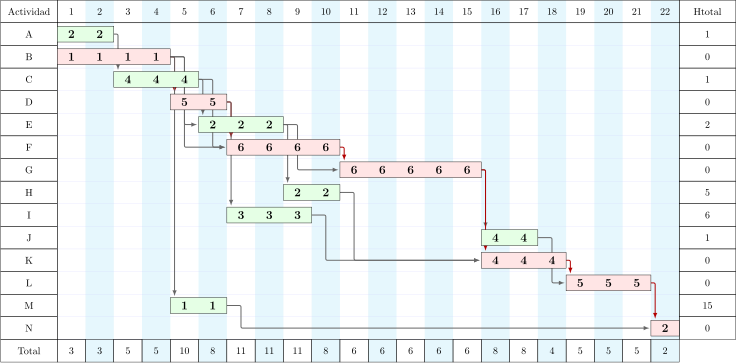

In [53]:
#| fig-cap: "Diagrama de Gantt del proyecto original con la demanda de operarios"
#| label: fig-ganttPreAsignacion
proyecto_asignacion = proyecto.copy()
gantt_df, dibujo = proyecto_asignacion.gantt(datos_proyecto, 'duration', 'resources', total='fila', holguras=True, tikz=True)
pinta_tikz(dibujo)

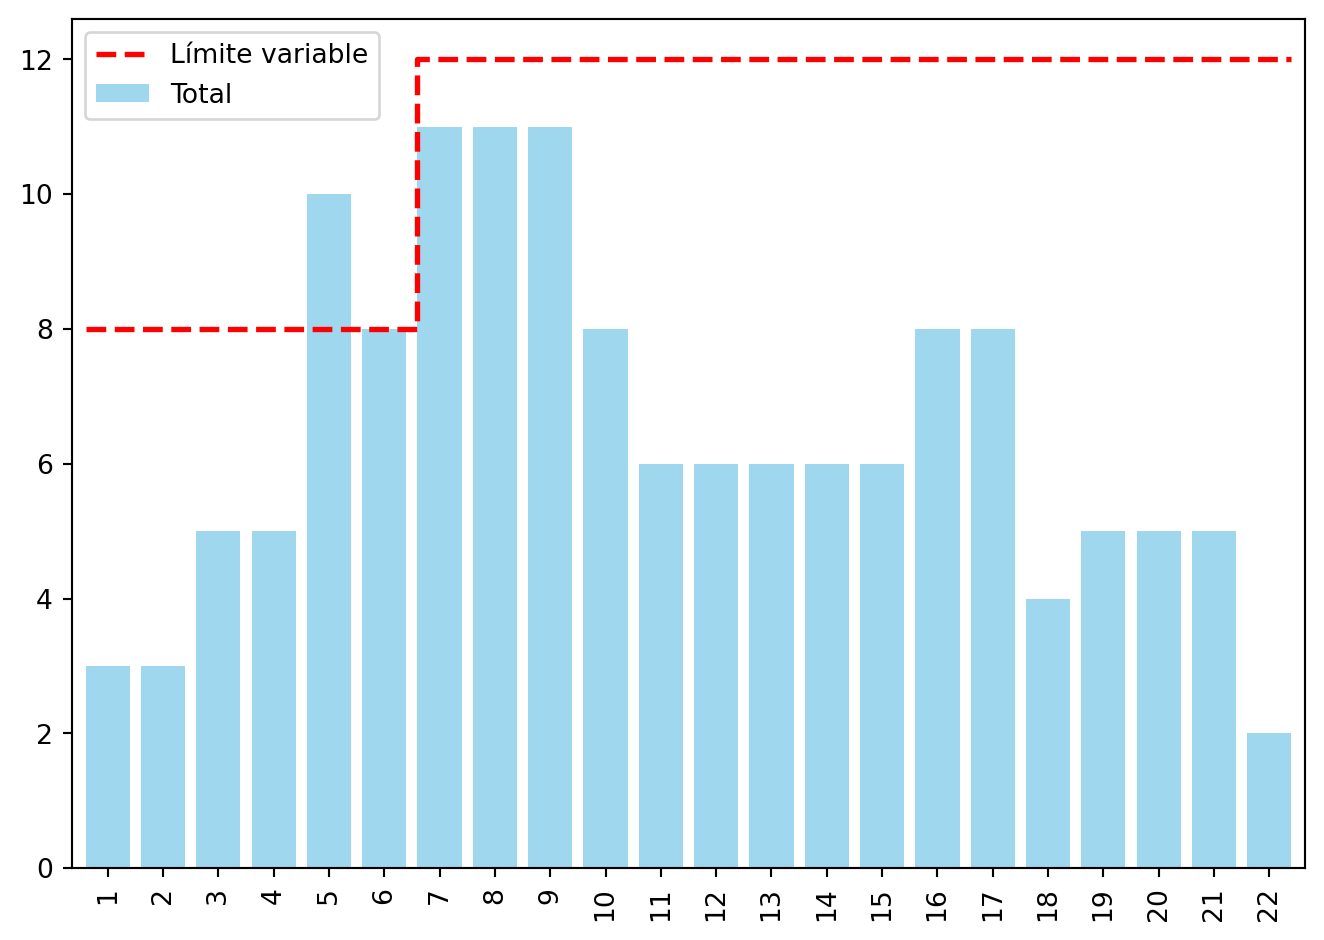

In [54]:
#| fig-cap: "Diagrama de cargas del proyecto original con indicación del límite de operarios"
#| label: fig-preAsignacionBarras
plot_cargas(gantt_df, limite_maximo_recursos)

La demanda supera el límite de operarios durante las primeras semanas. Es necesario aplicar el algoritmo de asignación.

### Algoritmo de asignación de Wiest-Levy

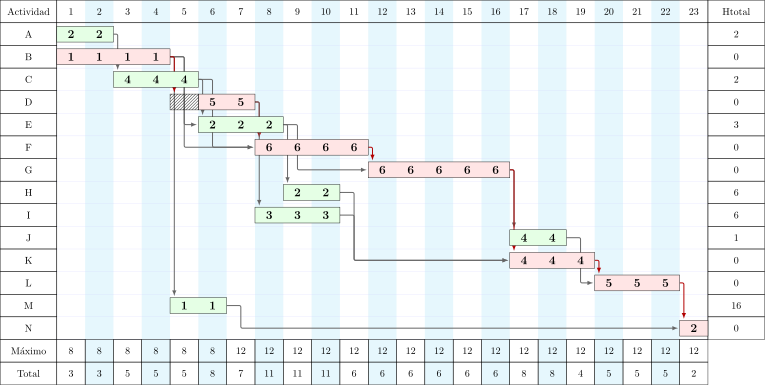

In [55]:
#| fig-cap: "Diagrama de Gantt del proyecto tras aplicar el algoritmo de asignación"
#| label: fig-ganttPostAsignacion
datos_tras_asignar, gantt_df, dibujo = proyecto_asignacion.asignar(data=datos_proyecto[['duration', 'resources']].copy(),
                                                                   duration_label='duration',
                                                                   resource_label='resources',
                                                                   maximo=limite_maximo_recursos,
                                                                   report=False)
pinta_tikz(dibujo)

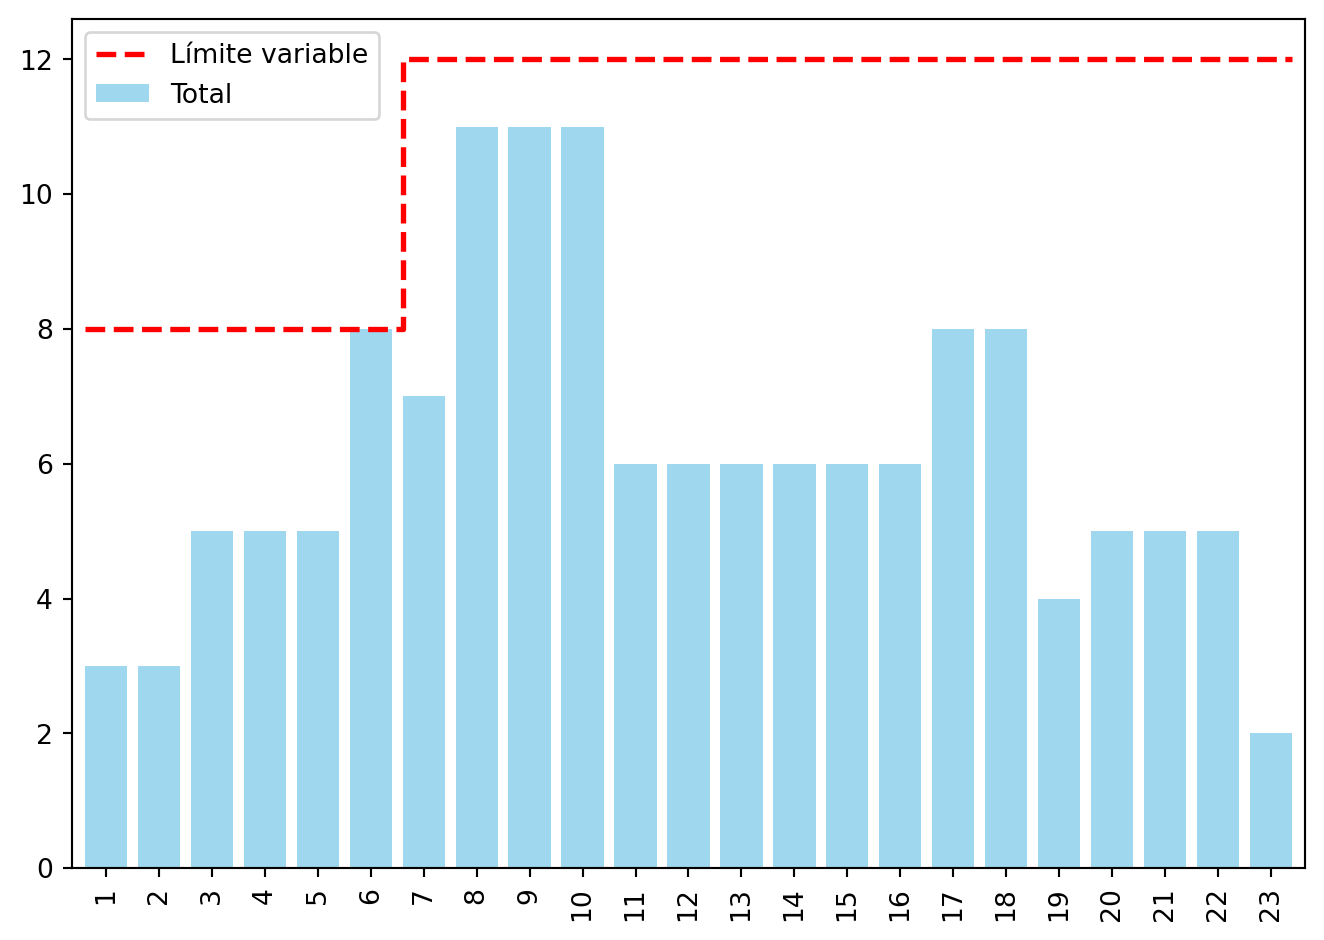

In [56]:
#| fig-cap: "Diagrama de cargas tras aplicar el algoritmo de asignación"
#| label: fig-postAsignacionBarras
plot_cargas(gantt_df, limite_maximo_recursos)

In [57]:
duracion_tras_asignar = int(gantt_df.data.columns.drop('H_total').max())
retraso = duracion_tras_asignar - duracion_media_proyecto
probabilidad_tras_asignar = norm.cdf(semana_nevada, loc=duracion_tras_asignar, scale=desviacion_proyecto)
from pmule import display_normal_tikz
display_normal_tikz(duracion_tras_asignar, desviacion_proyecto, hasta=semana_nevada)
if retraso > 0:
    conclusion = f"""Tras la asignación, la duración media del proyecto pasa a ser de **{duracion_tras_asignar} semanas**, {retraso} más que la planificación original. Si se mantiene la desviación típica original como aproximación, la probabilidad de terminar antes de la nevada cae al **{probabilidad_tras_asignar*100:.1f}%**.

La escasez de operarios al inicio es, por tanto, un riesgo serio. Las alternativas son contratar operarios adicionales durante esas semanas o combinar la asignación con la reducción del apartado 4. Esta segunda opción tiene un coste que podría compararse con el de contratar."""
else:
    conclusion = f"""Tras la asignación, la duración media del proyecto se mantiene en **{duracion_tras_asignar} semanas**. Las actividades desplazadas han consumido holgura, así que el proyecto cumple la restricción de operarios sin retrasarse. A cambio, ahora hay más actividades críticas y el riesgo frente a la nevada aumenta, aunque la duración media no cambie."""
Markdown(conclusion)

Tras la asignación, la duración media del proyecto pasa a ser de **23 semanas**, 1 más que la planificación original. Si se mantiene la desviación típica original como aproximación, la probabilidad de terminar antes de la nevada cae al **27.0%**.

La escasez de operarios al inicio es, por tanto, un riesgo serio. Las alternativas son contratar operarios adicionales durante esas semanas o combinar la asignación con la reducción del apartado 4. Esta segunda opción tiene un coste que podría compararse con el de contratar.

{{< pagebreak >}}

## Apartado 6

In [58]:
display(pregunta_6)

6. Partiendo del proyecto original: al final de la semana 11 se realiza un punto de control, cuyos datos se adjuntan.
    - Calcule PV, EV, AC, CPI, SPI y la estimación del coste final (EAC).
    - Estime la duración final del proyecto mediante el método de la programación ganada (*Earned Schedule*). ¿Llegará el refugio a tiempo?  

### Diagramas de Gantt del valor ganado

In [59]:
datos_valor_ganado = pd.concat([datos_proyecto[['predecessor', 'duration', 'BAC']], datos_seguimiento], axis=1)
vg = EarnedValue(proyecto)
gantts = vg.calcula_gantts(datos_valor_ganado,
                           planned_durations_label='duration',
                           actual_durations_label='actual_duration',
                           PV_label='BAC',
                           AC_label='AC',
                           percentage_complete_label='performed',
                           tikz=True,
                           params=dict(
                               period_width=1,
                               row_height=0.7,
                               activity_relative_height=0.6,
                               critical_background_color='white!90!green',
                               regular_background_color='white!90!green',
                               regular_text_color='black',
                               critical_text_color='black',
                               activity_inner_text_style=r"\bfseries\small",),
                           )

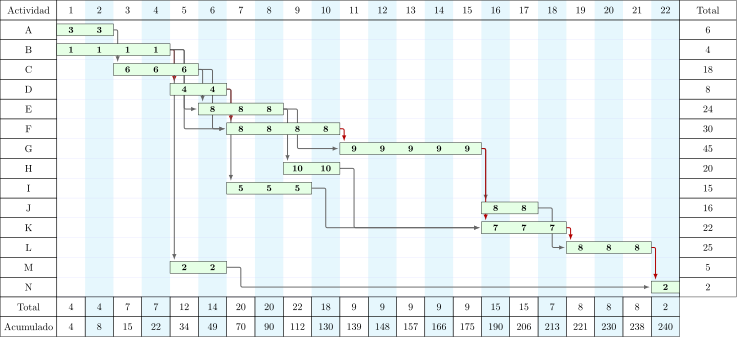

In [60]:
#| fig-cap: "PV: Valor planificado"
#| label: fig-ganttPV
pinta_tikz(gantts['gantt_PV'])

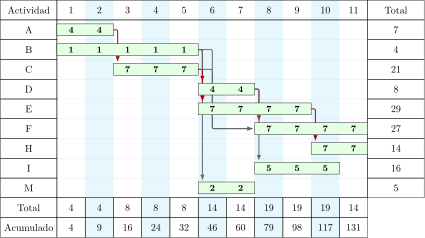

In [61]:
#| fig-cap: "AC: Coste real"
#| label: fig-ganttAC
pinta_tikz(gantts['gantt_AC'])

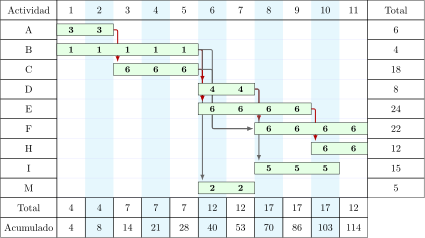

In [62]:
#| fig-cap: "EV: Valor ganado"
#| label: fig-ganttEV
pinta_tikz(gantts['gantt_EV'])

### Indicadores en el punto de control

In [63]:
acumulados = gantts['acumulados']
PV = float(acumulados.loc[semana_control, 'PV'])
EV = float((datos_valor_ganado['BAC'] * datos_valor_ganado['performed'] / 100).sum())
AC = float(datos_valor_ganado['AC'].sum())
BAC = float(BAC_total)

In [64]:
Markdown(f"""En la semana {semana_control}:
- PV = {PV:.1f} k€ (valor acumulado de la planificación original en la semana {semana_control})
- EV = Σ BAC · % realizado = {EV:.1f} k€
- AC = {AC:.1f} k€
- BAC = {BAC:.0f} k€  """)

En la semana 11:
- PV = 139.0 k€ (valor acumulado de la planificación original en la semana 11)
- EV = Σ BAC · % realizado = 114.5 k€
- AC = 131.0 k€
- BAC = 240 k€  

In [65]:
@handcalc(jupyter_display=False)
def indicadores_valor_ganado(EV, AC, PV, BAC):
    CPI = EV / AC
    SPI = EV / PV
    CV = EV - AC
    SV = EV - PV
    EAC = BAC / CPI
    VAC = BAC - EAC
latex_code, _ = indicadores_valor_ganado(EV, AC, PV, BAC)
Math(latex_code)

<IPython.core.display.Math object>

In [66]:
CPI, SPI = EV / AC, EV / PV
EAC = BAC / CPI
Markdown(f"""El proyecto va **por encima del presupuesto** (CPI = {CPI:.2f} < 1): por cada euro gastado se ha obtenido sólo {CPI:.2f} euros de valor. Si esta eficiencia se mantiene, el coste final será de unos {EAC:.0f} k€, frente a los {BAC:.0f} planificados. Además, el proyecto va **retrasado** (SPI = {SPI:.2f} < 1).""")

El proyecto va **por encima del presupuesto** (CPI = 0.87 < 1): por cada euro gastado se ha obtenido sólo 0.87 euros de valor. Si esta eficiencia se mantiene, el coste final será de unos 275 k€, frente a los 240 planificados. Además, el proyecto va **retrasado** (SPI = 0.82 < 1).

### Previsión de la duración mediante la programación ganada (*Earned Schedule*)

El SPI clásico se expresa en unidades monetarias y tiende a 1 al final de cualquier proyecto, aunque éste termine tarde. La programación ganada mide el adelanto o retraso en unidades de tiempo. Para ello busca en qué instante de la planificación original se había previsto alcanzar el valor que realmente se ha ganado:

$$ES = C + \frac{EV - PV_C}{PV_{C+1} - PV_C}$$

Aquí $C$ es el último periodo completo cuyo valor planificado acumulado $PV_C$ no supera EV. A partir de ES se calculan

$$SPI(t) = \frac{ES}{AT} \qquad IEAC(t) = \frac{PD}{SPI(t)}$$

siendo $AT$ el tiempo real transcurrido y $PD$ la duración planificada.

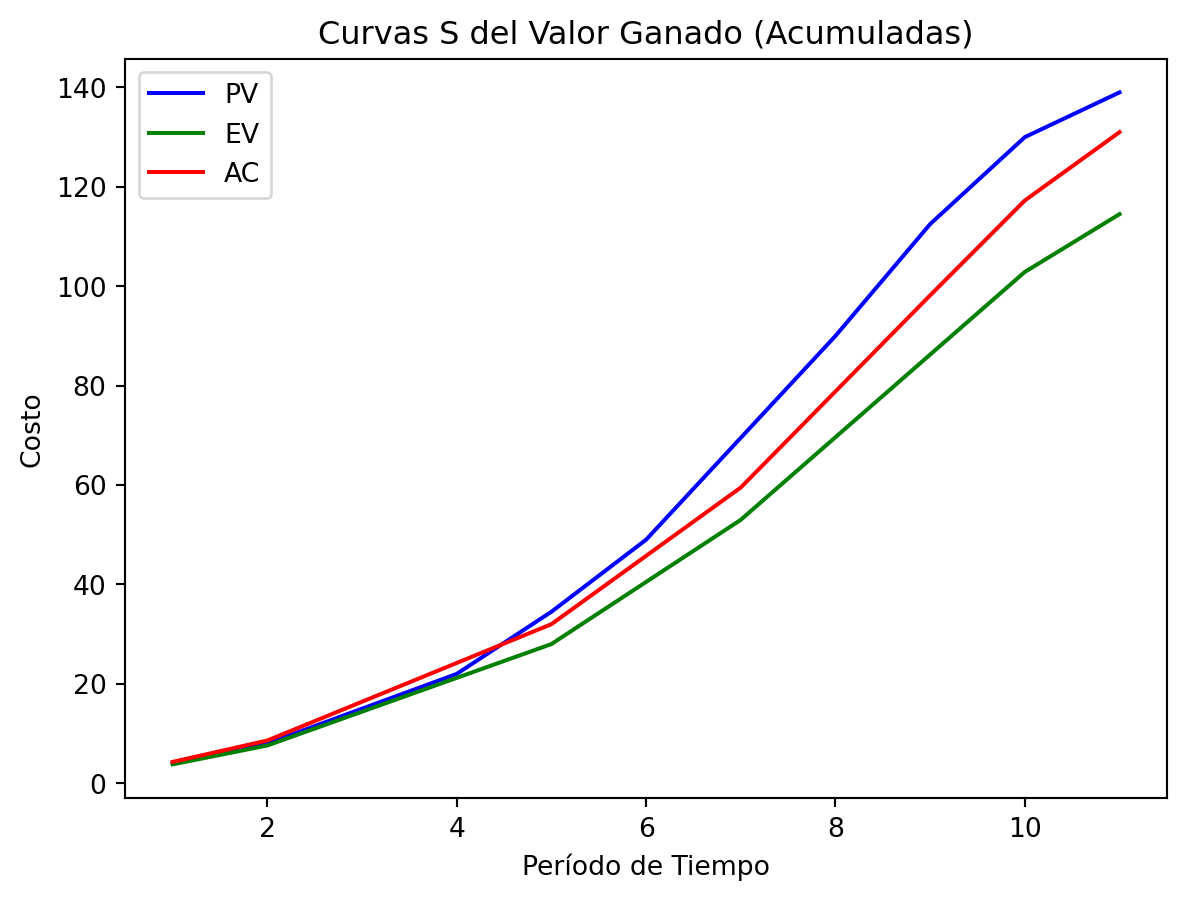

In [67]:
#| fig-cap: "Curvas S de valor planificado, valor ganado y coste real"
#| label: fig-curvasValorGanado
plot_curvas_valor_ganado(gantts)

In [68]:
pv_acumulado = pd.concat([pd.Series({0: 0.0}), acumulados['PV'].astype(float)])
C = int(pv_acumulado[pv_acumulado <= EV].index.max())
PV_C, PV_C1 = pv_acumulado[C], pv_acumulado[C + 1]
AT = semana_control
PD = duracion_media_proyecto

@handcalc(jupyter_display=False)
def programacion_ganada(C, EV, PV_C, PV_C1, AT, PD):
    ES = C + (EV - PV_C) / (PV_C1 - PV_C)
    SPI_t = ES / AT
    IEAC_t = PD / SPI_t
latex_code, _ = programacion_ganada(C, EV, PV_C, PV_C1, AT, PD)
Math(latex_code)

<IPython.core.display.Math object>

In [69]:
ES = C + (EV - PV_C) / (PV_C1 - PV_C)
IEAC_t = PD / (ES / AT)
Markdown(f"""El valor ganado hasta ahora ({EV:.1f} k€) se había previsto alcanzar en la semana {ES:.2f}. El proyecto acumula por tanto un retraso de **{AT - ES:.2f} semanas**. Si el ritmo actual se mantiene, la duración prevista es de **{IEAC_t:.1f} semanas**, **después de la nevada de la semana {semana_nevada}**.

Aunque aún faltan once semanas, la previsión es clara: con este ritmo, el refugio no se terminará a tiempo. Conviene poner en marcha ya las medidas de reducción del apartado 4 sobre las actividades que quedan: G, J, K y L son reducibles. Además, la actividad crítica G todavía no ha empezado, porque la cimentación (F) no ha terminado.""")

El valor ganado hasta ahora (114.5 k€) se había previsto alcanzar en la semana 9.11. El proyecto acumula por tanto un retraso de **1.89 semanas**. Si el ritmo actual se mantiene, la duración prevista es de **26.6 semanas**, **después de la nevada de la semana 22**.

Aunque aún faltan once semanas, la previsión es clara: con este ritmo, el refugio no se terminará a tiempo. Conviene poner en marcha ya las medidas de reducción del apartado 4 sobre las actividades que quedan: G, J, K y L son reducibles. Además, la actividad crítica G todavía no ha empezado, porque la cimentación (F) no ha terminado.